# 4.Model Training

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/diabetic_data_All_cleaned.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (101766, 41)


,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,...,tolazamide,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted_30
0,Caucasian,Female,[0-10),6,25,1,1,41,0,1,...,No,No,No,No,No,No,No,No,No,0
1,Caucasian,Female,[10-20),1,1,7,3,59,0,18,...,No,Up,No,No,No,No,No,Ch,Yes,0
2,AfricanAmerican,Female,[20-30),1,1,7,2,11,5,13,...,No,No,No,No,No,No,No,No,Yes,0
3,Caucasian,Male,[30-40),1,1,7,2,44,1,16,...,No,Up,No,No,No,No,No,Ch,Yes,0
4,Caucasian,Male,[40-50),1,1,7,1,51,0,8,...,No,Steady,No,No,No,No,No,Ch,Yes,0


In [3]:
X = df.drop(columns=["readmitted_30"])
y = df["readmitted_30"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (101766, 40)
y shape: (101766,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (81412, 40)
X_test : (20354, 40)
y_train: (81412,)
y_test : (20354,)


In [5]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 11
Categorical features: 29


In [6]:
numeric_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)

In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [8]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

In [9]:
print("Training Logistic Regression...")

logistic_model.fit(X_train, y_train)

print("Training completed!")

Training Logistic Regression...
Training completed!


In [10]:
y_pred = logistic_model.predict(X_test)

print("Predictions generated!")
print(y_pred[:20])

Predictions generated!
[1 0 1 1 1 0 0 0 1 1 0 1 0 0 0 1 0 0 0 1]


In [11]:
y_probability = logistic_model.predict_proba(X_test)[:, 1]

print(y_probability[:10])

[0.56461479 0.32234869 0.54752495 0.70921641 0.51007665 0.19431046
 0.31215488 0.34137882 0.73300812 0.65658501]


In [12]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_probability
)

print("========== LOGISTIC REGRESSION ==========")

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

========== LOGISTIC REGRESSION ==========
Accuracy : 0.6456
Precision: 0.1674
Recall   : 0.5478
F1 Score : 0.2565
ROC-AUC  : 0.6426


In [13]:
print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No 30-Day Readmission",
            "30-Day Readmission"
        ],
        zero_division=0
    )
)


Classification Report:

                       precision    recall  f1-score   support

No 30-Day Readmission       0.92      0.66      0.77     18083
   30-Day Readmission       0.17      0.55      0.26      2271

             accuracy                           0.65     20354
            macro avg       0.54      0.60      0.51     20354
         weighted avg       0.84      0.65      0.71     20354



In [14]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[11897  6186]
 [ 1027  1244]]


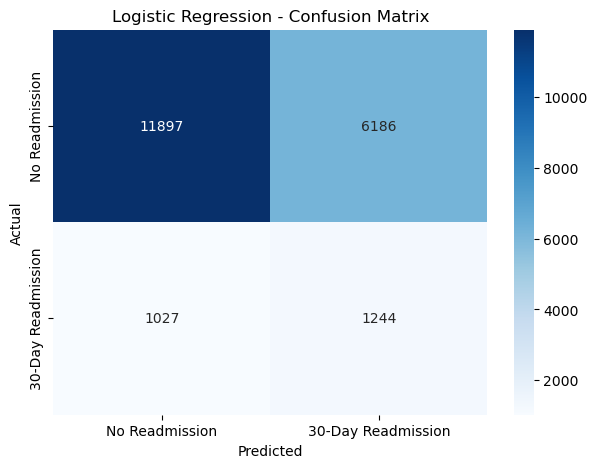

In [15]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Readmission",
        "30-Day Readmission"
    ],
    yticklabels=[
        "No Readmission",
        "30-Day Readmission"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

In [16]:
import joblib

joblib.dump(
    logistic_model,
    "../models/logistic_regression_model.pkl"
)

print("Logistic Regression pipeline saved successfully!")

Logistic Regression pipeline saved successfully!


In [17]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=None,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [18]:
print("Training Random Forest...")

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Training Random Forest...
Random Forest training completed!


In [19]:
rf_pred = random_forest_model.predict(X_test)

rf_probability = random_forest_model.predict_proba(X_test)[:, 1]

print("Predictions generated!")

Predictions generated!


In [20]:
rf_accuracy = accuracy_score(y_test, rf_pred)

rf_precision = precision_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_roc_auc = roc_auc_score(
    y_test,
    rf_probability
)

print("========== RANDOM FOREST ==========")

print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")
print(f"ROC-AUC  : {rf_roc_auc:.4f}")

========== RANDOM FOREST ==========
Accuracy : 0.8886
Precision: 0.6111
Recall   : 0.0048
F1 Score : 0.0096
ROC-AUC  : 0.6605


In [21]:
print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        rf_pred,
        target_names=[
            "No 30-Day Readmission",
            "30-Day Readmission"
        ],
        zero_division=0
    )
)


Classification Report:

                       precision    recall  f1-score   support

No 30-Day Readmission       0.89      1.00      0.94     18083
   30-Day Readmission       0.61      0.00      0.01      2271

             accuracy                           0.89     20354
            macro avg       0.75      0.50      0.48     20354
         weighted avg       0.86      0.89      0.84     20354



In [22]:
rf_cm = confusion_matrix(y_test, rf_pred)

print("Confusion Matrix:")
print(rf_cm)

Confusion Matrix:
[[18076     7]
 [ 2260    11]]


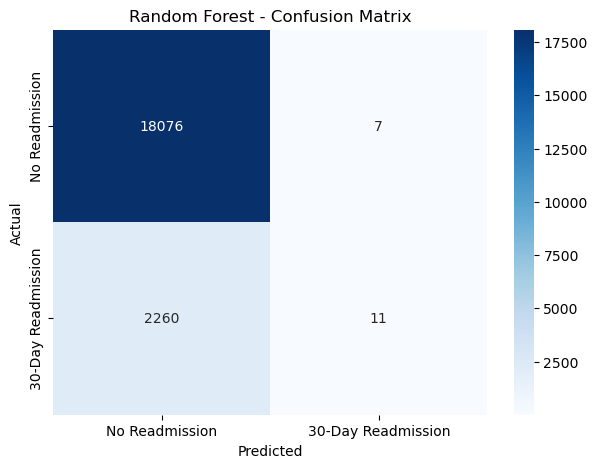

In [23]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Readmission",
        "30-Day Readmission"
    ],
    yticklabels=[
        "No Readmission",
        "30-Day Readmission"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")

plt.show()

In [24]:
from xgboost import XGBClassifier

In [25]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative samples:", negative_count)
print("Positive samples:", positive_count)
print("Scale pos weight:", scale_pos_weight)

Negative samples: 72326
Positive samples: 9086
Scale pos weight: 7.960158485582214


In [28]:
xgboost_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                n_estimators=300,
                max_depth=6,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                scale_pos_weight=scale_pos_weight,
                objective="binary:logistic",
                eval_metric="logloss",
                tree_method="hist",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [29]:
print("Training XGBoost...")

xgboost_model.fit(
    X_train,
    y_train
)

print("XGBoost training completed!")

Training XGBoost...
XGBoost training completed!


In [30]:
xgb_pred = xgboost_model.predict(X_test)

xgb_probability = xgboost_model.predict_proba(X_test)[:, 1]

In [31]:
xgb_accuracy = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred, zero_division=0)
xgb_recall = recall_score(y_test, xgb_pred, zero_division=0)
xgb_f1 = f1_score(y_test, xgb_pred, zero_division=0)
xgb_roc_auc = roc_auc_score(y_test, xgb_probability)

print("========== XGBOOST ==========")
print(f"Accuracy : {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall   : {xgb_recall:.4f}")
print(f"F1 Score : {xgb_f1:.4f}")
print(f"ROC-AUC  : {xgb_roc_auc:.4f}")

========== XGBOOST ==========
Accuracy : 0.6664
Precision: 0.1862
Recall   : 0.5905
F1 Score : 0.2831
ROC-AUC  : 0.6848


In [32]:
print(
    classification_report(
        y_test,
        xgb_pred,
        target_names=[
            "No 30-Day Readmission",
            "30-Day Readmission"
        ],
        zero_division=0
    )
)

                       precision    recall  f1-score   support

No 30-Day Readmission       0.93      0.68      0.78     18083
   30-Day Readmission       0.19      0.59      0.28      2271

             accuracy                           0.67     20354
            macro avg       0.56      0.63      0.53     20354
         weighted avg       0.85      0.67      0.73     20354



In [33]:
xgb_cm = confusion_matrix(y_test, xgb_pred)

print("XGBoost Confusion Matrix:")
print(xgb_cm)

XGBoost Confusion Matrix:
[[12222  5861]
 [  930  1341]]


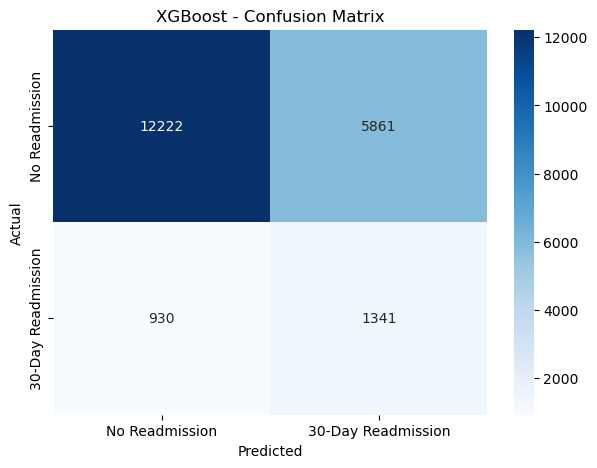

In [34]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    xgb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Readmission",
        "30-Day Readmission"
    ],
    yticklabels=[
        "No Readmission",
        "30-Day Readmission"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost - Confusion Matrix")
plt.show()

In [35]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy,
        rf_accuracy,
        xgb_accuracy
    ],
    "Precision": [
        precision,
        rf_precision,
        xgb_precision
    ],
    "Recall": [
        recall,
        rf_recall,
        xgb_recall
    ],
    "F1 Score": [
        f1,
        rf_f1,
        xgb_f1
    ],
    "ROC-AUC": [
        roc_auc,
        rf_roc_auc,
        xgb_roc_auc
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.645622,0.167429,0.547776,0.256468,0.642600
1,Random Forest,0.888621,0.611111,0.004844,0.009611,0.660466
2,XGBoost,0.666356,0.186198,0.590489,0.283120,0.684799


In [36]:
results_rounded = results.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

results_rounded[metric_columns] = results_rounded[
    metric_columns
].round(4)

results_rounded

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.6456,0.1674,0.5478,0.2565,0.6426
1,Random Forest,0.8886,0.6111,0.0048,0.0096,0.6605
2,XGBoost,0.6664,0.1862,0.5905,0.2831,0.6848


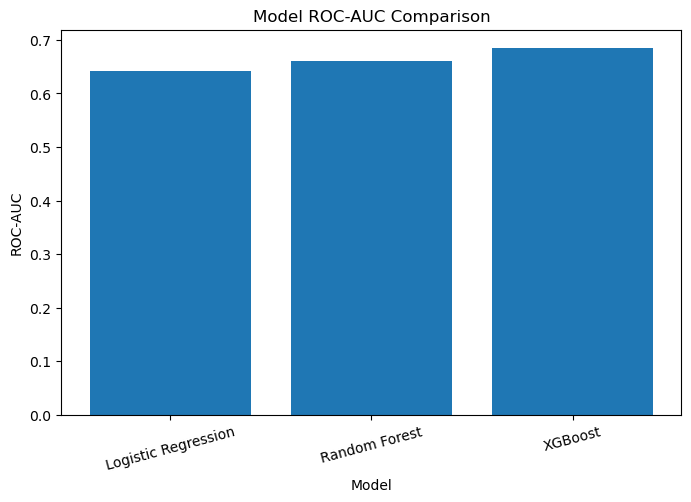

In [37]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["ROC-AUC"]
)

plt.ylabel("ROC-AUC")
plt.xlabel("Model")
plt.title("Model ROC-AUC Comparison")

plt.xticks(rotation=15)

plt.show()

In [38]:
joblib.dump(
    random_forest_model,
    "../models/random_forest_model.pkl"
)

joblib.dump(
    xgboost_model,
    "../models/xgboost_model.pkl"
)

print("All models saved successfully!")

All models saved successfully!


In [39]:
print("Random Forest Confusion Matrix:")
print(rf_cm)

print("\nXGBoost Confusion Matrix:")
print(xgb_cm)

print("\nLogistic Regression Confusion Matrix:")
logistic_cm = confusion_matrix(y_test, y_pred)
print(logistic_cm)

Random Forest Confusion Matrix:
[[18076     7]
 [ 2260    11]]

XGBoost Confusion Matrix:
[[12222  5861]
 [  930  1341]]

Logistic Regression Confusion Matrix:
[[11897  6186]
 [ 1027  1244]]


In [40]:
feature_names = xgboost_model.named_steps[
    "preprocessor"
].get_feature_names_out()

print("Number of features:", len(feature_names))

Number of features: 2271


In [41]:
xgb_classifier = xgboost_model.named_steps["classifier"]

feature_importance = xgb_classifier.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(20)

,Feature,Importance
9,num__number_inpatient,0.011139
1,num__discharge_disposition_id,0.005448
718,cat__diag_1_V57,0.003808
517,cat__diag_1_715,0.003807
911,cat__diag_2_342,0.003532
719,cat__diag_1_V58,0.003455
1582,cat__diag_3_286,0.003066
299,cat__diag_1_428,0.002984
1541,cat__diag_3_250.6,0.002695
148,cat__diag_1_250.6,0.002683


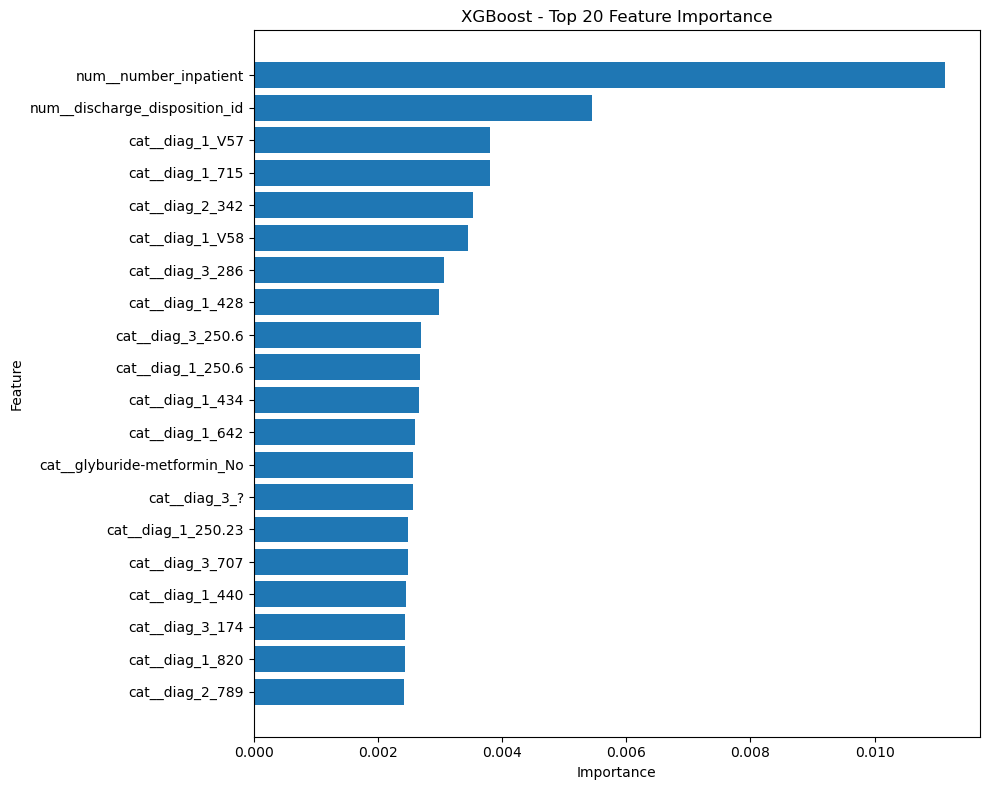

In [42]:
top_features = importance_df.head(20).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("XGBoost - Top 20 Feature Importance")

plt.tight_layout()
plt.show()

In [43]:
importance_df.to_csv(
    "../models/xgboost_feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [44]:
import joblib

joblib.dump(
    xgboost_model,
    "../models/final_xgboost_model.pkl"
)

print("Final XGBoost model saved successfully!")

Final XGBoost model saved successfully!


In [45]:
import os

model_path = "../models/final_xgboost_model.pkl"

print("Model exists:", os.path.exists(model_path))
print("Model size:", os.path.getsize(model_path), "bytes")

Model exists: True
Model size: 862767 bytes


In [46]:
loaded_model = joblib.load(
    "../models/final_xgboost_model.pkl"
)

print("Final model loaded successfully!")

Final model loaded successfully!


In [47]:
sample_patient = X_test.iloc[[0]]

prediction = loaded_model.predict(sample_patient)[0]
probability = loaded_model.predict_proba(sample_patient)[0][1]

print("Prediction:", prediction)
print(f"Readmission Probability: {probability:.2%}")

Prediction: 1
Readmission Probability: 53.77%


In [48]:
if prediction == 1:
    print("Prediction: 30-Day Readmission")
else:
    print("Prediction: No 30-Day Readmission")

print(f"Probability: {probability:.2%}")

Prediction: 30-Day Readmission
Probability: 53.77%
